# BIL545 · Proje 1
## 9.5 Online alışverişte satın alma niyeti

| | |
|---|---|
| Ders | Veri Madenciliğinde İleri Konular · 2026–2027 Güz |
| Öğrenci | Emircan Demir |
| Öğrenci numarası | 264309006 |
| Grup | Tek kişilik |
| GitHub | [Proje deposu](https://github.com/EmircanDemirTR/bil545-online-alisveris) |

**Araştırma sorusu.** Tamamlanmış oturumların gezinme özetleri ve ziyaret bilgileri, satın almayla biten oturumları ayırmaya ne kadar yardımcı olur?

Bu ayrım, mağaza ekibinin hangi oturum örüntülerini dönüşüm analizi için inceleyeceğine yardımcı olabilir. Veri bir oturumun anlık görüntülerini içermediği için erken müdahale başarısı bu deneyle ölçülemez.

## Hazırlık

İlk çalıştırmada veriyi UCI'dan indirmek için internet gerekir. Defter, çalışma klasöründe veya bir üstünde aynı adlı CSV'yi bulursa onu kullanır. Colab'da yerel kopyayı kullanmak için **Dosyalar** panelinden CSV'yi yüklemek yeterlidir.

In [1]:
import hashlib
import io
import sys
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

SEED = 42
np.random.seed(SEED)
print("Python", sys.version.split()[0])
for library in (np, pd, sklearn, matplotlib):
    print(library.__name__, library.__version__)

Python 3.12.10
numpy 2.5.3
pandas 3.0.6
sklearn 1.9.1
matplotlib 3.11.2


### Veriyi yükleme

**Kaynak** [UCI Machine Learning Repository](https://doi.org/10.24432/C5F88Q) · **Lisans** [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

Ham dosya çalışma deposunda yer almaz. Aşağıdaki hücre dosyayı okur ve kullanılan sürümün SHA-256 özetini yazdırır.

In [2]:
FILENAME = "online_shoppers_intention.csv"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"
paths = (Path(FILENAME), Path("..") / FILENAME)
local_csv = next((path for path in paths if path.is_file()), None)

if local_csv is None:
    with urlopen(UCI_ZIP, timeout=45) as response:
        with ZipFile(io.BytesIO(response.read())) as archive:
            csv_bytes = archive.read(FILENAME)
else:
    csv_bytes = local_csv.read_bytes()

print("Girdi:", "UCI arşivi" if local_csv is None else local_csv)
print("SHA-256:", hashlib.sha256(csv_bytes).hexdigest())

Girdi: UCI arşivi
SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9


# Bölüm 1 · Veri, ön işleme ve sızıntı

**Makale** [Kaufman, Rosset, Perlich ve Stitelman (2012)](https://doi.org/10.1145/2382577.2382579)

**Okuma notu.** Makale sızıntıyı, tahmin sırasında meşru biçimde kullanılabilecek bilgiye göre tanımlıyor. Dolayısıyla önce tahmin sorusu ve özniteliklerin hangi anda hesaplandığı belirlenmeli. Yazarların öğrenme ve tahmini ayırma ilkesi uyarınca doğrulama katını dönüştürmek için gereken istatistikleri eğitim katından öğreniyorum. Aynı ilke, satın alma bilgisinden türetilmiş olabilecek bir özniteliği Pipeline'a koymanın tek başına yeterli olmamasını da açıklıyor.

### 1.1 Veri künyesi

| Soru | Cevap |
|---|---|
| Kim, hangi amaçla topladı? | C. Okan Sakar, S. Olcay Polat, Mete Katircioglu ve Yomi Kastro'nun çalışması, bir e-ticaret sitesindeki ziyaretlerden satın alma ve siteyi terk etme olasılığını incelemek için gezinme verilerini kullandı. Açık tabloyu Sakar ve Kastro UCI'da yayımladı. |
| Hangi dönemi kapsıyor? | UCI, bir yıllık dönem ve her oturumun farklı bir kullanıcıya ait olması hedefiyle oluşturulmuş bir örneklem bildiriyor. Açık CSV'de yalnızca ayın adı var. 2018 veri kümesinin yayım yılıdır. CSV üzerinden toplama yılı veya gün düzeyinde sıra doğrulanamıyor. |
| Hedef gerçek olgu mu, vekil mi? | **Revenue**, oturumun satın almayla bitip bitmediğini kaydeden ikili sonuçtur. Gerçekleşen işlem gözleniyor. Ziyaretçinin niyetini ölçmek istenirse bu etiket vekildir. Satın almadan çıkan bir ziyaretçi de satın almayı düşünmüş olabilir. |
| Kimler eksik temsil ediliyor olabilir? | Veri bir mağazadan geliyor. Başka mağazaların ziyaretçileri ve yaş ya da gelir gibi gruplar için kapsama ve performans değerlendirilemiyor. Örneklemde az görülen trafik türlerinin ve ayların dönüşüm oranları daha az gözleme dayanıyor. |
| Lisans | Creative Commons Attribution 4.0 International (CC BY 4.0). |

In [3]:
df_raw = pd.read_csv(io.BytesIO(csv_bytes), na_values=["?"])
calendar = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = (
    df_raw.groupby("Month")["Revenue"].agg(["size", "sum", "mean"])
    .reindex(calendar)
    .rename(columns={"size": "Oturum", "sum": "Satın alma", "mean": "Satın alma oranı"})
)
display(by_month.style.format(
    {"Oturum": "{:.0f}", "Satın alma": "{:.0f}", "Satın alma oranı": "{:.2%}"},
    na_rep="—",
))

,Oturum,Satın alma,Satın alma oranı
Month,,,
Jan,—,—,—
Feb,184,3,1.63%
Mar,1907,192,10.07%
Apr,—,—,—
May,3364,365,10.85%
June,288,29,10.07%
Jul,432,66,15.28%
Aug,433,76,17.55%
Sep,448,86,19.20%


**Yorum.** Ocak ve nisan için satır yok. Mayıs ve kasım birlikte örneklemin yaklaşık yarısını oluşturuyor. Tablodaki ay oranları, bu örneklemin dağılımını gösteriyor. Tam tarih ve kampanya bilgisi olmadığından bu farkları mevsim etkisine bağlayamam.

### 1.2 Keşifsel analiz

Saklama tipi pandas'ın CSV'den okuduğu tipi, ölçüm ölçeği değişkenin nasıl yorumlandığını gösteriyor. Sıfır oranı yalnızca nicel sütunlarda hesaplanıyor. `False` ayrı bir kategoridir.

Ham tablo: 12,330 satır × 18 sütun


,Saklama,Ölçek,Eksik (%),Farklı değer,Sıfır (%)
Sütun,,,,,
Administrative,int64,Oran · sayım,0.00,27,46.78
Administrative_Duration,float64,Oran · süre,0.00,3335,47.88
Informational,int64,Oran · sayım,0.00,17,78.66
Informational_Duration,float64,Oran · süre,0.00,1258,80.49
ProductRelated,int64,Oran · sayım,0.00,311,0.31
ProductRelated_Duration,float64,Oran · süre,0.00,9551,6.12
BounceRates,float64,Oran · pay,0.00,1872,44.75
ExitRates,float64,Oran · pay,0.00,4777,0.62
PageValues,float64,Oran · metrik değer,0.00,2704,77.86


Tam tekrar, ilk satır hariç: 125
Seçili özniteliklerde ek tekrar: 6
Seçili öznitelikleri aynı, etiketleri farklı gruplar: 0


,Ham,Deney,Ham (%),Deney (%)
Satın alma yok,10422,10291,84.53,84.36
Satın alma var,1908,1908,15.47,15.64


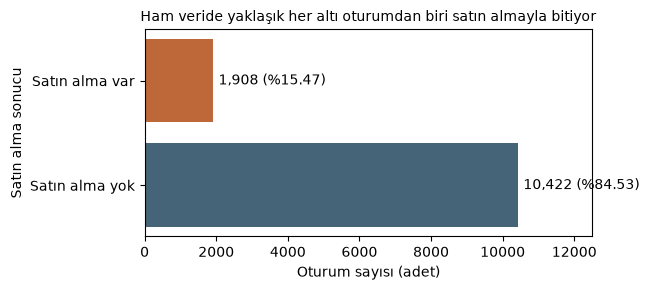

In [4]:
page_counts = ["Administrative", "Informational", "ProductRelated"]
durations = [f"{column}_Duration" for column in page_counts]
analytics = ["BounceRates", "ExitRates", "PageValues"]
nominal = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
target = "Revenue"
categorical = nominal + ["Weekend"]
numeric = page_counts + durations + ["SpecialDay"]
features = numeric + categorical
scale = {
    **dict.fromkeys(page_counts, "Oran · sayım"),
    **dict.fromkeys(durations, "Oran · süre"),
    "BounceRates": "Oran · pay",
    "ExitRates": "Oran · pay",
    "PageValues": "Oran · metrik değer",
    "SpecialDay": "Sıralı · yakınlık puanı",
    **dict.fromkeys(nominal, "Nominal kategori"),
    "Weekend": "İkili kategori",
    "Revenue": "İkili hedef",
}
assert set(df_raw.columns) == set(scale)
assert df_raw[target].isin([True, False]).all()

def audit_table(frame):
    rows = []
    for name, values in frame.items():
        rows.append({
            "Sütun": name,
            "Saklama": str(values.dtype),
            "Ölçek": scale[name],
            "Eksik (%)": 100 * values.isna().mean(),
            "Farklı değer": values.nunique(),
            "Sıfır (%)": 100 * values.eq(0).mean() if name in numeric + analytics else np.nan,
        })
    return pd.DataFrame(rows).set_index("Sütun")

print(f"Ham tablo: {df_raw.shape[0]:,} satır × {df_raw.shape[1]} sütun")
display(audit_table(df_raw).style.format(
    {"Eksik (%)": "{:.2f}", "Sıfır (%)": "{:.2f}"}, na_rep="—"
))

raw_duplicates = df_raw.duplicated()
df_unique = df_raw.loc[~raw_duplicates].copy()
feature_duplicates = df_unique.duplicated(subset=features)
same_features = df_unique.loc[df_unique.duplicated(subset=features, keep=False)]
conflicting_targets = (
    same_features.groupby(features, dropna=False)[target].nunique().gt(1).sum()
)
print(f"Tam tekrar, ilk satır hariç: {raw_duplicates.sum()}")
print(f"Seçili özniteliklerde ek tekrar: {feature_duplicates.sum()}")
print(f"Seçili öznitelikleri aynı, etiketleri farklı gruplar: {conflicting_targets}")
assert conflicting_targets == 0, "Öznitelikleri aynı ama etiketleri farklı oturumlar incelenmeli."
df_clean = df_unique.loc[~feature_duplicates].reset_index(drop=True)
X = df_clean[features].copy()
y = df_clean[target].astype(int)

class_counts = pd.DataFrame({
    "Ham": df_raw[target].value_counts(),
    "Deney": df_clean[target].value_counts(),
}).reindex([False, True])
class_counts.index = ["Satın alma yok", "Satın alma var"]
for name in ["Ham", "Deney"]:
    class_counts[f"{name} (%)"] = 100 * class_counts[name] / class_counts[name].sum()
display(class_counts.style.format({"Ham (%)": "{:.2f}", "Deney (%)": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(6.5, 3))
bars = ax.barh(class_counts.index, class_counts["Ham"], color=["#456478", "#be6738"])
ax.bar_label(bars, labels=[
    f"{count:,} (%{pct:.2f})"
    for count, pct in zip(class_counts["Ham"], class_counts["Ham (%)"])
], padding=4)
ax.set(xlabel="Oturum sayısı (adet)", ylabel="Satın alma sonucu", xlim=(0, 12500))
ax.set_title("Ham veride yaklaşık her altı oturumdan biri satın almayla bitiyor", fontsize=10)
plt.tight_layout()
plt.show()

**Yorum.** Ham veride 12.330 oturum ve hedef dahil 18 sütun var. Satın alma oranı %15,47. Tam tekrar olan 125 satır ile ana modelin girdilerinde eşleşen 6 ek satırın hepsi negatif sınıftaydı. Kopyaları ayrı katlara dağıtmamak için her örüntüden ilk satırı tuttum. Oturum kimliği bulunmadığından bu satırlar aynı şekilde davranan farklı oturumlar da olabilir. Ayıklama sonrası 12.199 oturum kaldı ve pozitif oranı %15,64'e çıktı.

| Denetlenen sütun | Karar ve gerekçe |
|---|---|
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Sayısal görünen kodlar kategori belirtir. Örneğin 8 numaralı tarayıcının 4 numaralı tarayıcının iki katı gibi bir anlamı yok. Oturum ya da kullanıcı kimliği saptanmadı. |
| `VisitorType=Other`, sürelerdeki sıfırlar, `SpecialDay=0` | Belgelenmiş bir eksik kodu olmadığı için değerleri korudum. Özel güne yakın olunmadığında sıfır, anlamlı bir değer. |
| `PageValues` | Google Analytics'in işlemle ilişkili sayfa değeri. Hesap penceresi CSV'den doğrulanamadığı için ana modelde kullanmadım. |
| `BounceRates`, `ExitRates` | Çıkışı da kullanan toplu sayfa ölçüleri. Geçmişten dondurulmuş istatistikler olarak mı yoksa aynı dönemin tamamından mı üretildiği açık olmadığı için ana modelden çıkardım. |
| Sayfa sayıları ve süreleri | Oturum özeti olarak kullanılabilir. Oturum tamamlanmadan verilecek bir karar için yalnızca o ana kadarki değerlerin yeniden üretilmesi gerekir. |

### 1.3 Eksiklik analizi

Önce metin olarak okunan CSV'de boş hücre ve yaygın eksik işaretlerini arıyorum. Sonra kaynakta doğrulanan eksik verinin yokluğunu satır ve sütun düzeyinde denetliyorum. İki sütunlu gösterge deneyi için yapay bir ölçüm kaybı oluşturuyorum.

Aday eksik işareti sayısı: 0
NaN'a dönüşen veya doğal olarak eksik hücre: 0


,Oturum sayısı
Oturum başına eksik hücre,
0,12330


,Sayfa yok ve süre 0,Sayfa var ve süre 0
Süre,,
Administrative_Duration,5768,135
Informational_Duration,9699,226
ProductRelated_Duration,38,717


,Administrative_Duration,Informational_Duration,Oturum sayısı
0,var,var,9673
1,eksik,var,1523
2,var,eksik,809
3,eksik,eksik,194


,Ham CSV,MAR benzetimi
Administrative_Duration,0.00%,14.07%
Informational_Duration,0.00%,8.22%


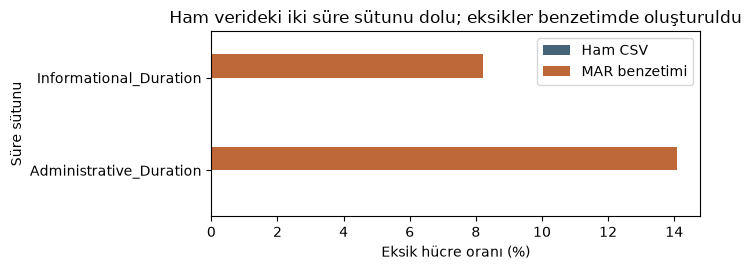

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Medyan,0.2998 ± 0.0184,0.7133 ± 0.0103,0.5127 ± 0.0040,0.0611 ± 0.0137,0.0328 ± 0.0076
Medyan + gösterge,0.3002 ± 0.0192,0.7152 ± 0.0102,0.5127 ± 0.0042,0.0619 ± 0.0147,0.0333 ± 0.0082


Göstergenin eşleştirilmiş AP farkı: +0.0004 ± 0.0035


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

raw_tokens = pd.read_csv(io.BytesIO(csv_bytes), dtype=str, keep_default_na=False)
missing_tokens = {"", "?", "na", "n/a", "nan", "null"}
token_mask = raw_tokens.apply(lambda column: column.str.strip().str.lower().isin(missing_tokens))
print("Aday eksik işareti sayısı:", token_mask.sum().sum())
print("NaN'a dönüşen veya doğal olarak eksik hücre:", df_raw.isna().sum().sum())
patterns = df_raw.isna().sum(axis=1).value_counts().sort_index()
display(patterns.rename_axis("Oturum başına eksik hücre").to_frame("Oturum sayısı"))
assert not token_mask.any().any() and not df_raw.isna().any().any(), "Eksik desenini yeniden inceleyin."

zero_audit = pd.DataFrame([
    {
        "Süre": duration,
        "Sayfa yok ve süre 0": (df_raw[count].eq(0) & df_raw[duration].eq(0)).sum(),
        "Sayfa var ve süre 0": (df_raw[count].gt(0) & df_raw[duration].eq(0)).sum(),
    }
    for count, duration in zip(page_counts, durations)
]).set_index("Süre")
display(zero_audit)

# Ölçüm kaybı, ilgili kategoride sayfa gören oturumlarda uygulanır.
# Olasılık gözlenen sayaçtan gelir ve etiketi kullanmaz.
rng = np.random.default_rng(SEED)
X_missing = X.copy()
simulated = ["Administrative_Duration", "Informational_Duration"]
for duration in simulated:
    visited = X[duration.removesuffix("_Duration")]
    probability = np.select([visited.eq(0), visited.le(2)], [0.0, 0.50], default=0.12)
    X_missing[duration] = X[duration].mask(rng.random(len(X)) < probability)

pattern = (
    X_missing[simulated].isna()
    .replace({False: "var", True: "eksik"})
    .value_counts(sort=False).rename("Oturum sayısı").reset_index()
)
display(pattern)
missing_rates = pd.DataFrame({
    "Ham CSV": 100 * df_raw.isna().mean(),
    "MAR benzetimi": 100 * X_missing.isna().mean(),
}).loc[simulated]
display(missing_rates.style.format("{:.2f}%"))
ax = missing_rates.plot.barh(figsize=(7.2, 2.8), color=["#456478", "#be6738"])
ax.set(xlabel="Eksik hücre oranı (%)", ylabel="Süre sütunu",
       title="Ham verideki iki süre sütunu dolu; eksikler benzetimde oluşturuldu")
plt.tight_layout()
plt.show()

outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
splits = list(outer_cv.split(X, y))
SCORING = {
    "AP": "average_precision",
    "ROC AUC": "roc_auc",
    "Dengeli doğruluk": "balanced_accuracy",
    "F1": "f1",
    "Duyarlılık": "recall",
}

def preprocessing(traffic_encoder=None, indicator=False, extra_numeric=()):
    num = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=indicator)),
        ("scale", StandardScaler()),
    ])
    if traffic_encoder is None:
        traffic_encoder = OneHotEncoder(handle_unknown="ignore")
    other_categories = [c for c in categorical if c != "TrafficType"]
    return ColumnTransformer([
        ("sayisal", num, numeric + list(extra_numeric)),
        ("kategori", OneHotEncoder(handle_unknown="ignore"), other_categories),
        ("trafik", traffic_encoder, ["TrafficType"]),
    ])

def logistic(preprocessor):
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=1000)),
    ])

def fold_scores(estimator, data, cv=splits):
    evaluated = cross_validate(estimator, data, y, cv=cv, scoring=SCORING, error_score="raise")
    return pd.DataFrame({name: evaluated[f"test_{name}"] for name in SCORING})

def score_summary(results):
    return pd.DataFrame({
        name: table.apply(lambda column: f"{column.mean():.4f} ± {column.std():.4f}")
        for name, table in results.items()
    }).T

def paired_ap(first, second):
    delta = second["AP"] - first["AP"]
    return f"{delta.mean():+.4f} ± {delta.std():.4f}"

missing_scores = {
    "Medyan": fold_scores(logistic(preprocessing()), X_missing),
    "Medyan + gösterge": fold_scores(logistic(preprocessing(indicator=True)), X_missing),
}
display(score_summary(missing_scores))
print("Göstergenin eşleştirilmiş AP farkı:", paired_ap(*missing_scores.values()))

**Yorum.** Gerçek tabloda en çok eksiği olan iki sütun seçilemiyor çünkü her sütunda eksik sayısı sıfır. Bu yüzden ham veri için MCAR, MAR veya MNAR sonucu çıkarmadım. İdari ve bilgi sayfası sürelerini seçmemin nedeni, sayfa görülüp görülmediğinin ayrı bir sayaçtan anlaşılması. Sayfa sayısı sıfırken süre sıfır olması yapısal bir sıfırla uyumlu. Sayfa sayısı pozitifken sıfır sürenin nedeni ise bu tablodan ayırt edilemiyor.

Benzetimde `Administrative_Duration` ve `Informational_Duration` için eksilme olasılığı aynı gruptaki **gözlenen** sayfa sayısına bağlı. Bu yüzden ikisi için de mekanizma tasarım gereği MAR. Eksilme süreye bakılarak seçilseydi MNAR olabilirdi. Hedef, maskelemede kullanılmadı. Gösterge AP'yi 0,2998'den 0,3002'ye taşıdı. Eşleştirilmiş fark +0,0004 ± 0,0035: bu benzetimde gözlenen kazanım küçük ve katlara göre değişiyor. Sayfa sayısı zaten modelde bulunduğu için göstergenin taşıdığı bilginin bir kısmı elindeydi.

### 1.4 Kategorik kodlama

`TrafficType` veri kümesindeki en çok düzeye sahip kategorik sütun. Yirmi kategoriden bazıları tek oturumda görülüyor. Diğer öznitelikleri, modeli ve dış katları sabit tutarak yalnızca bu sütunun kodlamasını değiştiriyorum.

In [6]:
traffic_counts = X["TrafficType"].value_counts().sort_index()
display(traffic_counts.rename_axis("Trafik kodu").to_frame("Oturum sayısı").T)
print("20'den az gözlemli kategori sayısı:", traffic_counts.lt(20).sum())

def traffic_target_encoder():
    options = {"target_type": "binary", "smooth": 10}
    sklearn_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
    if sklearn_version >= (1, 9):
        inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
        return TargetEncoder(cv=inner_cv, **options)
    return TargetEncoder(cv=5, random_state=SEED, **options)

onehot = logistic(preprocessing())
rare = logistic(preprocessing(
    traffic_encoder=OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist")
))
target_encoded = logistic(preprocessing(traffic_encoder=traffic_target_encoder()))

# Bilerek yanlış: doğrulama etiketleri kategori ortalamalarına giriyor.
traffic = X[["TrafficType"]]
global_traffic = traffic_target_encoder().fit(traffic, y).transform(traffic)
X_wrong_encoding = X.assign(TrafficType=global_traffic.ravel())
fixed_numeric_traffic = logistic(preprocessing(traffic_encoder="passthrough"))

encoding_scores = {
    "One-hot": fold_scores(onehot, X),
    "Nadirleri birleştiren one-hot": fold_scores(rare, X),
    "Kat dışı hedef kodlama": fold_scores(target_encoded, X),
    "Tüm etiketlerle hedef kodlama (yanlış)": fold_scores(fixed_numeric_traffic, X_wrong_encoding),
}
display(score_summary(encoding_scores))
print("Yanlış − kat dışı kodlama, eşleştirilmiş AP farkı:",
      paired_ap(encoding_scores["Kat dışı hedef kodlama"],
                encoding_scores["Tüm etiketlerle hedef kodlama (yanlış)"]))

Trafik kodu,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Oturum sayısı,2384,3910,2013,1066,260,443,40,343,41,450,247,1,728,13,37,3,1,10,17,192


20'den az gözlemli kategori sayısı: 6


,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
One-hot,0.2998 ± 0.0183,0.7132 ± 0.0103,0.5128 ± 0.0038,0.0616 ± 0.0134,0.0331 ± 0.0074
Nadirleri birleştiren one-hot,0.2999 ± 0.0185,0.7132 ± 0.0105,0.5128 ± 0.0039,0.0614 ± 0.0137,0.0330 ± 0.0076
Kat dışı hedef kodlama,0.3002 ± 0.0179,0.7132 ± 0.0106,0.5108 ± 0.0040,0.0538 ± 0.0134,0.0287 ± 0.0073
Tüm etiketlerle hedef kodlama (yanlış),0.3020 ± 0.0182,0.7153 ± 0.0107,0.5114 ± 0.0040,0.0562 ± 0.0136,0.0301 ± 0.0075


Yanlış − kat dışı kodlama, eşleştirilmiş AP farkı: +0.0018 ± 0.0010


**Yorum.** Nadir düzey eşiği eğitim katı başına 20 gözlem. Nadir düzeyleri birleştirmek tek tük gözlemlerden ayrı katsayı öğrenmeyi önlüyor, ama gerçekten farklı trafik türlerini de aynı kovaya koyabiliyor. Hedef kodlamada iç katlar eğitim satırlarının kodunu kendi hedefinden ayırıyor. Dış doğrulamadaki bir satır, yalnızca dış eğitimden öğrenilmiş kodla dönüştürülüyor. Yanlış örnekte dış doğrulama etiketleri de trafik ortalamasına karışıyor. Özellikle tek gözlemli kategorilerde bu işlem satırın kendi etiketi hakkında bilgi taşıyor. Yanlış kodlamanın AP'si 0,3020, kat dışı kodlamanınki 0,3002. Geçerli üç yöntem arasındaki fark dört ondalık basamakta 0,0004'ü aşmadı. Bu nedenle ana hatta açıklaması daha kolay olan one-hot ile devam ettim.

### 1.5 Sızıntı deneyi

İlk karşılaştırmada medyan doldurma, ölçekleme ve one-hot adımlarını, katların dışında yanlışlıkla tüm tabloya uyguluyorum. Bu deney etiketi kullanan kodlamadan ayrı. İkinci karşılaştırmada Pipeline'ı aynı tutuyor, yalnızca `PageValues` ekliyorum. Bu iki karşılaştırma farklı sorunları ölçüyor.

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Kat içinde ön işleme,0.2998 ± 0.0183,0.7132 ± 0.0103,0.5128 ± 0.0038,0.0616 ± 0.0134,0.0331 ± 0.0074
Tüm veride ön işleme (yanlış),0.2998 ± 0.0185,0.7132 ± 0.0104,0.5128 ± 0.0039,0.0614 ± 0.0137,0.0330 ± 0.0076
Kat içinde + PageValues (riskli),0.6374 ± 0.0212,0.8939 ± 0.0078,0.6772 ± 0.0113,0.5002 ± 0.0223,0.3803 ± 0.0235


Tüm veri − kat içi AP farkı: +0.0000 ± 0.0003
PageValues ile − PageValues olmadan AP farkı: +0.3376 ± 0.0203


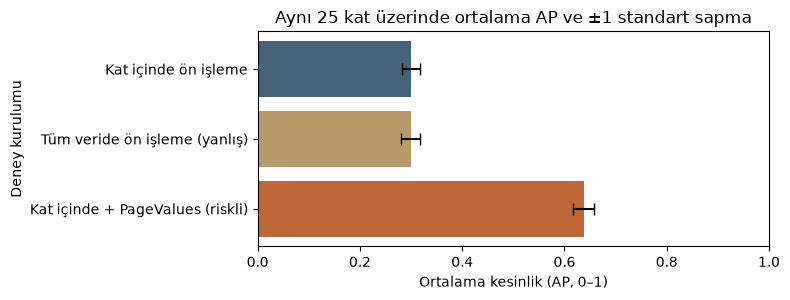

,Oturum,Satın alma,Satın alma oranı
PageValues,,,
PageValues = 0,9469,370,3.91%
PageValues > 0,2730,1538,56.34%


In [7]:
# Bilerek yanlış: StandardScaler ve kodlayıcı test katının X değerlerini görüyor.
all_preprocessed = preprocessing().fit_transform(X)
global_score = fold_scores(LogisticRegression(max_iter=1000), all_preprocessed)

page_value_score = fold_scores(
    logistic(preprocessing(extra_numeric=["PageValues"])),
    X.assign(PageValues=df_clean["PageValues"]),
)
correct_score = encoding_scores["One-hot"]
leakage_scores = {
    "Kat içinde ön işleme": correct_score,
    "Tüm veride ön işleme (yanlış)": global_score,
    "Kat içinde + PageValues (riskli)": page_value_score,
}
display(score_summary(leakage_scores))
print("Tüm veri − kat içi AP farkı:", paired_ap(correct_score, global_score))
print("PageValues ile − PageValues olmadan AP farkı:", paired_ap(correct_score, page_value_score))

means = [table["AP"].mean() for table in leakage_scores.values()]
stds = [table["AP"].std() for table in leakage_scores.values()]
fig, ax = plt.subplots(figsize=(8, 3.1))
ax.barh(list(leakage_scores), means, xerr=stds, capsize=4,
        color=["#456478", "#b79b6b", "#be6738"])
ax.invert_yaxis()
ax.set(xlabel="Ortalama kesinlik (AP, 0–1)", ylabel="Deney kurulumu",
       title="Aynı 25 kat üzerinde ortalama AP ve ±1 standart sapma", xlim=(0, 1))
plt.tight_layout()
plt.show()

page_groups = (
    df_clean.groupby(df_clean["PageValues"].gt(0))[target].agg(["size", "sum", "mean"])
    .rename(index={False: "PageValues = 0", True: "PageValues > 0"},
            columns={"size": "Oturum", "sum": "Satın alma", "mean": "Satın alma oranı"})
)
display(page_groups.style.format({"Satın alma oranı": "{:.2%}"}))

**Yorum.** Ön işleme tüm veriden öğrenildiğinde model doğrulama etiketlerini görmüyor, fakat eğitimde kullanılmaması gereken doğrulama girdileri ortalama, sapma ve kategori sözlüğüne giriyor. Bu veri üzerinde iki kurulumun da AP'si dört basamakla 0,2998 çıktı. Eksik hücre olmadığı için medyan doldurma kullanılmadı. Kategori sözlüğü ve ölçeklemedeki farklar da bu modelde sonucu çok az değiştirdi. İki skorun yakınlığı, tüm veride ön işlemeyi geçerli kılmaz.

`PageValues` içeren hat, ön işleme açısından doğru bölünse bile özniteliğin kendisi satın alma olayıyla ilişkili bilgiden hesaplanmış olabilir. AP 0,2998'den 0,6374'e çıktı. `PageValues` pozitifken satın alma oranı yaklaşık %56, sıfırken yaklaşık %4. Bu fark özniteliği denetlemek için bir işaret, tek başına sızıntı kanıtı sayılmaz. Tarihsel sayfa değerleri geçmişten dondurulmuş ve tahmin anında elde edilebiliyorsa sütun kullanılabilir. Açık tabloda bu koşulu doğrulayamadığım için ana skoru o sütun olmadan raporluyorum. Hata çubukları katlar arasındaki dağılımı gösteriyor. Katlar bağımsız olmadığından güven aralığı olarak yorumlamıyorum.

### 1.6 Baseline ve ilk model

`DummyClassifier(strategy="most_frequent")` her oturum için çoğunluk sınıfını seçiyor. Lojistik regresyon aynı 5 kat × 5 tekrar üzerinde çalışıyor. Ana ölçüt **AP** (average precision, ortalama kesinlik), pozitif sınıfın sıralamadaki konumunu, karar eşiğine bağlanmadan özetliyor. ROC AUC'yi sıralama için, dengeli doğruluk, F1 ve duyarlılığı varsayılan eşikteki kararlar için ekledim.

In [8]:
dummy = Pipeline([
    ("preprocess", preprocessing()),
    ("model", DummyClassifier(strategy="most_frequent")),
])
main_scores = {
    "Dummy · çoğunluk": fold_scores(dummy, X),
    "Lojistik regresyon": correct_score,
}
display(score_summary(main_scores))
print("Lojistik − Dummy, eşleştirilmiş AP farkı:", paired_ap(*main_scores.values()))

# Dış katlar model deneylerinin tamamında aynı satır indekslerini kullanır.
for train, test in splits:
    assert not np.intersect1d(train, test).size
    assert len(train) + len(test) == len(X)
    assert y.iloc[test].nunique() == 2
assert len(splits) == 25 and not X.duplicated().any()

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Dummy · çoğunluk,0.1564 ± 0.0002,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Lojistik regresyon,0.2998 ± 0.0183,0.7132 ± 0.0103,0.5128 ± 0.0038,0.0616 ± 0.0134,0.0331 ± 0.0074


Lojistik − Dummy, eşleştirilmiş AP farkı: +0.1434 ± 0.0183


**Yorum.** Dummy'nin AP değeri pozitif sınıf payına yakın, dengeli doğruluğu 0,50 ve duyarlılığı sıfır. Çünkü hiçbir oturumu satın alma olarak işaretlemiyor. Lojistik regresyonun AP'si 0,2998, ROC AUC'si 0,7132. Yine de 0,5 eşiğinde pozitif oturumların ortalama yalnızca %3,3'ünü yakalıyor. Bir sıralama ölçütünün iyileşmesi, kullanılan eşikteki kararların yeterli olduğu anlamına gelmiyor. Bir mağazada bu eşik, kaçırılan satın alma ile gereksiz müdahalenin maliyetine göre ayrıca seçilmeli. Bu bölümde eşik veya hiperparametre araması yapmadım.

### 1.7 Weka ile bağımsız kontrol

Weka 3.8.6'da ZeroR ve J48, Python'la aynı 12.199 oturum, aynı 14 öznitelik ve aynı hedefle çalışıyor. Python'daki ölçeklenmiş matrisi aktarmak yerine bu tabloyu ARFF'ye dönüştürüyorum. Sayıyla saklanan kategoriler ARFF'de nominal, hedef `{False,True}`. Her model Weka'nın kendi tohumlu ve katmanlı 10 kat değerlendirmesini kullanıyor.

Aşağıdaki hücre Java ile Weka'yı doğrudan çağırır ve Weka'nın çıktı özetini deftere yazar. Colab'da Java hazır değilse hücre OpenJDK kurar. Yerel çalıştırma için Java komutunun PATH üzerinde bulunması gerekir.

In [9]:
import os
import shutil
import subprocess
from tempfile import TemporaryDirectory

from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, f1_score, recall_score, roc_auc_score,
)

java = shutil.which("java")
if java is None and "google.colab" in sys.modules:
    subprocess.run(["apt-get", "-qq", "update"], check=True, timeout=180)
    subprocess.run(["apt-get", "-qq", "install", "-y", "openjdk-17-jre-headless"],
                   check=True, timeout=240)
    java = shutil.which("java")
if java is None:
    raise RuntimeError("Weka için Java kurup java komutunu PATH'e ekleyin veya Colab kullanın.")

weka_data = X.assign(Revenue=y.astype(bool))
arff_lines = ["@relation online_shoppers"]
for column in weka_data:
    if column in categorical + [target]:
        levels = ",".join(map(str, sorted(weka_data[column].unique())))
        arff_lines.append(f"@attribute {column} {{{levels}}}")
    else:
        arff_lines.append(f"@attribute {column} numeric")

arff_text = ("\n".join(arff_lines + ["@data"]) + "\n" +
             weka_data.to_csv(header=False, index=False, lineterminator="\n"))

maven = "https://repo.maven.apache.org/maven2/nz/ac/waikato/cms/weka"
jars = {
    "weka-stable/3.8.6/weka-stable-3.8.6.jar":
        "932ea2f342b58fe45736389e9c426d5b5955e610d1f5f6485117f532068915e9",
    "thirdparty/bounce/0.18/bounce-0.18.jar":
        "bffff1505335c02256b7ab2ccffbe4aa4d3ac9fe14c17557809b7c9d99d666ca",
}

weka_commands = {"Weka ZeroR": "rules.ZeroR", "Weka J48": "trees.J48"}
weka_scores = {}
with TemporaryDirectory(prefix="bil545-") as directory:
    work = Path(directory)
    classpath = []
    for jar, expected_sha in jars.items():
        with urlopen(f"{maven}/{jar}", timeout=45) as response:
            content = response.read()
        if hashlib.sha256(content).hexdigest() != expected_sha:
            raise ValueError(f"Weka bağımlılığının SHA-256 değeri eşleşmedi: {jar}")
        jar_file = work / Path(jar).name
        jar_file.write_bytes(content)
        classpath.append(str(jar_file))

    arff = work / "online_shoppers.arff"
    arff.write_text(arff_text, encoding="ascii")

    for name, classifier in weka_commands.items():
        predictions = work / "predictions.csv"
        csv_options = (
            'weka.classifiers.evaluation.output.prediction.CSV '
            f'-file "{predictions.as_posix()}" -suppress -distribution -decimals 12'
        )
        command = [
            java, "-Djava.awt.headless=true", "-Dfile.encoding=UTF-8",
            "-Duser.language=en", "-Duser.country=US", "-cp", os.pathsep.join(classpath),
            f"weka.classifiers.{classifier}", "-t", str(arff), "-c", "last",
            "-x", "10", "-s", str(SEED), "-v", "-o",
        ]
        # Weka CLI, özet ve satır tahminlerini iki farklı çıktı kipinde verir.
        java_options = {"cwd": work, "capture_output": True, "text": True,
                        "encoding": "utf-8", "errors": "replace", "timeout": 90}
        summary = subprocess.run(command, **java_options)
        run = subprocess.run(command + ["-classifications", csv_options], **java_options)
        if summary.returncode or "Stratified cross-validation" not in summary.stdout:
            raise RuntimeError(f"{name} (özet)\n{summary.stdout}\n{summary.stderr}")
        if run.returncode or not predictions.is_file():
            raise RuntimeError(f"{name} (tahminler)\n{run.stdout}\n{run.stderr}")
        report = summary.stdout[summary.stdout.index("==="):].strip()
        print(f"\n{name} · Weka 3.8.6\n{report}")

        pred = pd.read_csv(
            predictions, header=None, skiprows=1, usecols=[0, 1, 2, 5],
        )
        pred.columns = ["instance", "actual", "predicted", "positive_probability"]
        pred["fold"] = pred["instance"].eq(1).cumsum()
        assert pred["fold"].nunique() == 10 and len(pred) == len(y)
        actual_all = pred["actual"].str.endswith(":True")
        assert actual_all.sum() == y.sum()
        metrics = []
        for _, group in pred.groupby("fold", sort=True):
            actual = group["actual"].str.endswith(":True")
            predicted = group["predicted"].str.endswith(":True")
            probability = group["positive_probability"].astype(str).str.lstrip("*").astype(float)
            metrics.append({
                "AP": average_precision_score(actual, probability),
                "ROC AUC": roc_auc_score(actual, probability),
                "Dengeli doğruluk": balanced_accuracy_score(actual, predicted),
                "F1": f1_score(actual, predicted, zero_division=0),
                "Duyarlılık": recall_score(actual, predicted),
            })
        weka_scores[name] = pd.DataFrame(metrics)
        predictions.unlink()

python_10fold = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
comparison = {
    "Python Dummy": fold_scores(dummy, X, cv=python_10fold),
    "Python lojistik": fold_scores(onehot, X, cv=python_10fold),
    **weka_scores,
}
display(score_summary(comparison))


Weka ZeroR · Weka 3.8.6
=== Stratified cross-validation ===

Correctly Classified Instances       10291               84.3594 %
Incorrectly Classified Instances      1908               15.6406 %
Kappa statistic                          0     
Mean absolute error                      0.2639
Root mean squared error                  0.3632
Relative absolute error                100      %
Root relative squared error            100      %
Total Number of Instances            12199     


=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 1.000    1.000    0.844      1.000    0.915      ?        0.500     0.843     False
                 0.000    0.000    ?          0.000    ?          ?        0.500     0.156     True
Weighted Avg.    0.844    0.844    ?          0.844    ?          ?        0.500     0.736     


=== Confusion Matrix ===

     a     b   <-- classified as
 10291     0 | 


Weka J48 · Weka 3.8.6
=== Stratified cross-validation ===

Correctly Classified Instances       10264               84.138  %
Incorrectly Classified Instances      1935               15.862  %
Kappa statistic                          0.0927
Mean absolute error                      0.2453
Root mean squared error                  0.3594
Relative absolute error                 92.947  %
Root relative squared error             98.9377 %
Total Number of Instances            12199     


=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 0.983    0.921    0.852      0.983    0.913      0.138    0.646     0.892     False
                 0.079    0.017    0.459      0.079    0.134      0.138    0.646     0.264     True
Weighted Avg.    0.841    0.780    0.790      0.841    0.791      0.138    0.646     0.793     


=== Confusion Matrix ===

     a     b   <-- classified as
 10114   177 |   

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Python Dummy,0.1564 ± 0.0003,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Python lojistik,0.3030 ± 0.0275,0.7128 ± 0.0156,0.5134 ± 0.0061,0.0633 ± 0.0216,0.0341 ± 0.0119
Weka ZeroR,0.1564 ± 0.0003,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Weka J48,0.2430 ± 0.0283,0.6311 ± 0.0490,0.5307 ± 0.0122,0.1335 ± 0.0388,0.0786 ± 0.0243


**Yorum.** Weka çıktısındaki doğruluk, çoğunluk sınıfının büyüklüğünü kontrol etmek için yararlı. ZeroR ve Python Dummy aynı davranışı gösteriyor: satın alma sınıfı hiç tahmin edilmiyor. Karşılaştırma tablosunda AP, Weka'nın kat tahminlerinden scikit-learn ile aynı tanımla hesaplandı. Weka'nın dökümünde görünen PRC Area ve AP farklı hesaplanabildiğinden o sütunu doğrudan Python AP ile kıyaslamadım.

J48, C4.5 tabanlı bir karar ağacı. Lojistik regresyondan farklı bir model öğreniyor ve Weka ile Python aynı sayıda kat kullanmalarına rağmen satırları bire bir aynı katlara dağıtmıyor. J48'in AP'si 0,2430 ± 0,0283, ZeroR'ınki 0,1564 ± 0,0003. J48 toplamda 1.908 pozitif oturumun 150'sini yakalarken genel doğruluğu ZeroR'dan biraz daha düşük çıktı (%84,14 ve %84,36). Bu, çoğunluk sınıfının doğruluk ölçütüne ne kadar yön verdiğini gösteriyor. Python tarafında da lojistik regresyon çoğunluk tahmininden daha iyi sıralama yaptı. Lojistik regresyonun AP'si daha yüksek, varsayılan eşikteki duyarlılığı J48'den daha düşük. Bu gözlemleri farklı modellerin ve bölmelerin aynı davranışı vermesini beklemeden yorumluyorum.

**Weka Explorer'da açmak için.** Yukarıdaki hücre çalıştıktan sonra yeni bir hücrede `Path("online_shoppers_bolum1.arff").write_text(arff_text, encoding="ascii")` çalıştır. Weka Explorer → **Preprocess → Open file** ile dosyayı aç. **Classify** sekmesinde `Revenue` hedefini, **Cross-validation** için 10 katı ve **More options** altında seed 42'yi seç. `rules → ZeroR` ve `trees → J48` modellerini varsayılan ayarlarıyla ayrı ayrı çalıştır.

## Varsayım defteri

- **Gözlem birimi:** Her satırı oturum kabul ettim. Farklı kullanıcılardan örnekleme bilgisi UCI'ya dayanıyor; dosyada kullanıcı anahtarı yok.
- **Tahmin anı:** Soru, tamamlanan oturumların geriye dönük karşılaştırması. Kaufman vd.'nin öğrenme ve tahmini ayırma ilkesini uygulayarak hesaplanma penceresi belirsiz Analytics metriklerini ana hattan çıkardım ve `PageValues` etkisini ayrı ölçtüm.
- **Tekrarlar:** Tam tekrar ve ana modelde aynı girdileri taşıyan satırlar, model kurulmadan önce ayıklandı. Gerekçe aynı örüntünün eğitim ve doğrulamaya dağılmasını önlemek. Eğer oturum kimliği olsaydı oturum bazında gruplama, eşit girdili farklı oturumları koruma olanağı verirdi.
- **Eksikler:** Gerçek veride doğrulanmış eksik yok. İki süreye, etiket kullanılmadan, gözlenen sayfa sayısına bağlı MAR uygulandı. Oranlar etkisi ölçülebilecek bir benzetim tasarımıdır. Medyan, sağa çarpık sürelerde uçlardan ortalamaya göre daha az etkilenir.
- **Kodlama:** Kodları nominal tuttum. Nadir kategori için mutlak 20 gözlem, hedef ortalaması için 10 düzeyinde yumuşatma kullandım. Bu değerler skor tarayarak seçilmedi. Eğitimde görülmeyen kodlar normal one-hot'ta sıfır, nadir one-hot'ta varsa nadir grubu, hedef kodlamada ise eğitim ortalamasıyla karşılanıyor.
- **Ölçekleme:** Süre, sayım ve takvim puanı farklı aralıklarda. L2 düzenlemeli lojistik model için nicel sütunlar eğitim katında standardize edildi.
- **Ölçüt ve bölme:** Pozitif sınıf az olduğu için AP ana ölçüt. 5 × 5 katmanlı bölme her deneyde sabit. Tam tarih olmadığı için ileri zamana genellenebilirlik bu veriyle sınanmadı. Kat standart sapmasını belirsizlik aralığı olarak kullanmadım.
- **Weka:** Aynı temiz tablo nominal alanlar korunarak dışa aktarıldı. Python ile aynı model ailesini taklit etmek yerine yönergedeki ZeroR ve J48 varsayılanları kullanıldı.

## Katkı beyanı

| Üye | Çalışma kapsamı | Sunum için planlanan alt başlıklar |
|---|---|---|
| Emircan Demir | Konu ve veri seçimi; Bölüm 1.1–1.7'nin tek kişilik proje kapsamı. Defterin ilk uygulaması ve doğrulaması aşağıdaki AI desteğiyle hazırlandı. | 1.3 eksiklik deneyi, 1.4–1.5 sızıntı, 1.6–1.7 Python ve Weka karşılaştırması |

## Yapay zekâ beyanı

OpenAI Codex, yönergenin incelenmesi, Python ve Weka deneylerinin tasarlanıp uygulanması, çıktıların doğrulanması ve sonuç yorumlarının ilk taslağının hazırlanması için kullanıldı.

## Kaynaklar

- Sakar, C. O. ve Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. [Veri kümesi ve lisans](https://doi.org/10.24432/C5F88Q).
- Sakar, C. O., Polat, S. O., Katircioglu, M. ve Kastro, Y. (2019). Real-time prediction of online shoppers’ purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications, 31*, 6893–6908. [Makale](https://doi.org/10.1007/s00521-018-3523-0).
- Kaufman, S., Rosset, S., Perlich, C. ve Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD, 6*(4), 15. [Makale](https://doi.org/10.1145/2382577.2382579).
- scikit-learn. [TargetEncoder ve kat dışı kodlama](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_target_encoder_cross_val.html), [average_precision_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
- University of Waikato. [Weka 3.8.6](https://github.com/Waikato/weka-3.8/blob/master/wekadocs/README), [komut satırı örnekleri](https://waikato.github.io/weka-wiki/primer/).